# Avatar EEG signal quality and prediction withholding

This notebook contains the complete core Python pipeline, then examines **real Data_clean recordings**. It never invents cues, task labels, quality labels or commands. The live GUI integrations remain in the project; this notebook does not connect to a headset, server or drone.

Flow: original physical EEG → acquisition checks and quality features → accept / withhold → existing classifier only after acceptance → fresh approval check before dispatch.

**Passing means passing configured checks. It does not establish correct intent decoding.** No independently reviewed quality labels currently exist, so the measured rejection rate is not detector accuracy.

## 1. Setup
Run top to bottom using an environment with `signal_quality/requirements-dev.txt`. Embedded sources are reconstructed in a temporary directory, leaving the project and original recordings untouched. Edit these paths if moving the notebook.

In [1]:
from pathlib import Path
import hashlib, json, sys, tempfile, os
os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="avatar-quality-mpl-"))
PROJECT_ROOT = Path("/home/prasndhdl/Downloads/avatar/Tellekynezix")
RAW_ROOT = Path("/home/prasndhdl/Downloads/Data_clean")
REPLAY_DIR = PROJECT_ROOT / "signal_quality/data/real_replay_v2"
TEMP_ROOT = Path(tempfile.mkdtemp(prefix="avatar-quality-notebook-"))
PACKAGE_DIR = TEMP_ROOT / "signal_quality"
PACKAGE_DIR.mkdir()
print("Embedded package:", PACKAGE_DIR)


Embedded package: /tmp/avatar-quality-notebook-4itcd43w/signal_quality


## 2. `__init__.py`

Public API: raw assessor, policy configuration and prediction gate.

In [2]:
%%writefile {PACKAGE_DIR / "__init__.py"}
"""Avatar raw EEG quality assessment and prediction withholding."""

from .assessment import QualityAssessor, QualityConfig
from .gate import QualityGatedPredictor, may_execute, withheld_result

__all__ = ["QualityAssessor", "QualityConfig", "QualityGatedPredictor", "may_execute", "withheld_result"]


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/__init__.py


## 3. `assessment.py`

Raw quality features and configurable rules. Inspect original microvolt EEG before filtering or normalization; otherwise saturation, flat channels and amplitude faults can be hidden. Spectral indicators alone do not diagnose eye or muscle artifacts.

In [3]:
%%writefile {PACKAGE_DIR / "assessment.py"}
"""Inspect original physical EEG before filtering or normalization.

Rules flag acquisition faults and gross contamination. Scores are descriptive,
not calibrated probabilities or proof that a task can be decoded. Spectral
features are indicators rather than physiological artifact diagnoses.
"""

from dataclasses import asdict, dataclass
import hashlib
import json

import numpy as np
from scipy.signal import welch


VERSION = "avatar-raw-quality-v1"
PER_CHANNEL_FEATURES = ("ptp_uv", "std_uv", "max_jump_uv", "flat_fraction", "rail_fraction",
                        "delta_ratio", "theta_ratio", "alpha_ratio", "beta_ratio",
                        "high_ratio", "line50_ratio", "line60_ratio", "spectral_entropy")
FEATURE_NAMES = tuple(f"{name}_{stat}" for name in PER_CHANNEL_FEATURES for stat in ("mean", "max", "min"))


@dataclass(frozen=True)
class QualityConfig:
    min_seconds: float = 2.0
    min_ptp_uv: float = 1e-6
    flat_step_uv: float = 1e-6
    max_flat_fraction: float = .98
    max_ptp_uv: float = 1000.0
    max_jump_uv: float = 500.0
    rail_uv: float = 187499.99
    max_rail_fraction: float = .01
    mains_hz: float | None = None
    max_line_ratio: float = .35
    max_arrival_gap_seconds: float = .5
    max_prediction_age_seconds: float = 10.0
    recovery_good_windows: int = 1

    def __post_init__(self):
        values = asdict(self)
        for name, value in values.items():
            if name in ("mains_hz", "recovery_good_windows"):
                continue
            if isinstance(value, bool) or not isinstance(value, (int, float)) or not np.isfinite(value) or value <= 0:
                raise ValueError(f"{name} must be positive and finite")
        for name in ("max_flat_fraction", "max_rail_fraction", "max_line_ratio"):
            if not 0 < values[name] <= 1:
                raise ValueError(f"{name} must be in (0,1]")
        if self.mains_hz is not None and (isinstance(self.mains_hz, bool) or self.mains_hz not in (50, 60)):
            raise ValueError("mains_hz must be verified 50/60, or None")
        if isinstance(self.recovery_good_windows, bool) or not isinstance(self.recovery_good_windows, int) or self.recovery_good_windows < 1:
            raise ValueError("recovery_good_windows must be a positive integer")

    @property
    def policy_id(self):
        digest = hashlib.sha256(json.dumps(asdict(self), sort_keys=True, separators=(",", ":")).encode()).hexdigest()[:16]
        return f"{VERSION}-{digest}"


class QualityAssessor:
    def __init__(self, config=None, *, quality_model=None):
        self.config = config if isinstance(config, QualityConfig) else QualityConfig(**(config or {}))
        self.quality_model = quality_model
        if quality_model is not None and quality_model.policy_id != self.config.policy_id:
            raise ValueError("Learned quality model policy differs from assessment config")

    def assess(self, raw, *, sfreq, channels, units, counters=None, timestamps=None,
               counter_step=None, counter_modulus=256, timestamp_kind="arrival", signal_stage="raw"):
        """Assess [channels,samples]; physical channel mapping is caller-supplied.

        Arrival timestamps are not treated as uniformly spaced sample clocks.
        Hardware counters catch missing packets; zero-phase filtering never runs
        here. All rows supplied to a downstream predictor are checked.
        """
        cfg = self.config
        raw = np.asarray(raw)
        if (raw.ndim != 2 or not raw.size or not np.issubdtype(raw.dtype, np.number)
                or np.iscomplexobj(raw)):
            raise ValueError("Require nonempty real raw EEG [channels,samples]")
        if (not isinstance(channels, (list, tuple)) or len(channels) != len(raw)
                or any(not isinstance(name, str) or not name.strip() for name in channels)
                or len(set(channels)) != len(channels)):
            raise ValueError("Require explicit unique physical channel names in input order")
        if isinstance(sfreq, bool) or not isinstance(sfreq, (int, float)) or not np.isfinite(sfreq) or sfreq <= 2:
            raise ValueError("Require a finite acquisition sampling rate above 2 Hz")
        if units != "uV" or signal_stage != "raw":
            raise ValueError("Quality assessment requires original raw physical EEG in uV")
        if timestamp_kind not in ("arrival", "sample"):
            raise ValueError("timestamp_kind must be arrival or sample")
        reasons, warnings = [], []
        channel_reasons = [[] for _ in channels]
        features = None
        numeric = raw.astype(np.float64, copy=False)
        if numeric.shape[1] < int(np.ceil(cfg.min_seconds * sfreq)):
            reasons.append("insufficient_samples")
        if not np.isfinite(numeric).all():
            reasons.append("nonfinite_eeg")
            for i in range(len(channels)):
                if not np.isfinite(numeric[i]).all():
                    channel_reasons[i].append("nonfinite_eeg")
        numerically_safe = np.isfinite(numeric).all() and np.max(np.abs(numeric)) < 1e12
        if np.isfinite(numeric).all() and not numerically_safe:
            reasons.append("out_of_range_eeg")
            for i in range(len(channels)):
                if (np.abs(numeric[i]) >= 1e12).any():
                    channel_reasons[i].append("out_of_range_eeg")
        if counters is not None:
            values = np.asarray(counters)
            if (values.shape != (raw.shape[1],) or not np.issubdtype(values.dtype, np.number)
                    or np.iscomplexobj(values) or not np.isfinite(values).all()
                    or (values != np.round(values)).any() or (values < 0).any()
                    or isinstance(counter_modulus, bool) or not isinstance(counter_modulus, int)
                    or counter_modulus <= 1 or (values >= counter_modulus).any()
                    or isinstance(counter_step, bool) or not isinstance(counter_step, int)
                    or not 0 < counter_step < counter_modulus):
                raise ValueError("Invalid hardware counter schema/values")
            if (np.mod(np.diff(values), counter_modulus) != counter_step).any():
                reasons.append("packet_discontinuity")
        else:
            warnings.append("hardware_counter_unavailable")
        if timestamps is not None:
            values = np.asarray(timestamps)
            if (values.shape != (raw.shape[1],) or not np.issubdtype(values.dtype, np.number)
                    or np.iscomplexobj(values) or not np.isfinite(values).all()):
                raise ValueError("Invalid timestamp schema/values")
            differences = np.diff(values)
            if (differences < 0).any() or (timestamp_kind == "sample" and (differences == 0).any()):
                reasons.append("nonmonotonic_time")
            if not (differences > 0).any():
                reasons.append("nonadvancing_time")
            if (differences > cfg.max_arrival_gap_seconds).any():
                reasons.append("acquisition_gap")
            if timestamp_kind == "sample" and not np.allclose(differences, 1 / sfreq, rtol=.2, atol=1e-6):
                reasons.append("sample_clock_rate_mismatch")
        else:
            warnings.append("timestamps_unavailable")
        if cfg.mains_hz is None:
            warnings.append("mains_frequency_unverified_line_ratios_informational")
        elif cfg.mains_hz + 1 >= sfreq / 2:
            reasons.append("mains_band_not_resolvable")
        if numerically_safe and raw.shape[1] >= 2:
            jumps = np.abs(np.diff(numeric, axis=1))
            ptp = np.ptp(numeric, axis=1)
            std = numeric.std(axis=1)
            flat = (jumps <= cfg.flat_step_uv).mean(axis=1)
            rail = (np.abs(numeric) >= cfg.rail_uv).mean(axis=1)
            f, psd = welch(numeric, fs=sfreq, window="hann", nperseg=min(raw.shape[1], int(round(2 * sfreq))),
                           detrend="constant", axis=-1, scaling="density")
            usable_band = (f >= 1) & (f <= sfreq / 2)
            total = psd[:, usable_band].sum(axis=1)
            def ratio(low, high):
                band = (f >= low) & (f < high)
                return np.divide(psd[:, band].sum(axis=1), total, out=np.zeros(len(raw)), where=total > 0)
            p = np.divide(psd[:, usable_band], total[:, None], out=np.zeros_like(psd[:, usable_band]), where=total[:, None] > 0)
            entropy = -(p * np.log(np.maximum(p, 1e-300))).sum(axis=1) / np.log(max(p.shape[1], 2))
            matrix = np.column_stack((ptp, std, jumps.max(axis=1), flat, rail,
                         ratio(1, 4), ratio(4, 8), ratio(8, 13), ratio(13, 30), ratio(30, 40),
                         ratio(49, 51), ratio(59, 61), entropy))
            features = {name: matrix[:, i].tolist() for i, name in enumerate(PER_CHANNEL_FEATURES)}
            for i in range(len(channels)):
                for name, bad in (("flat_channel", ptp[i] <= cfg.min_ptp_uv or flat[i] >= cfg.max_flat_fraction),
                                  ("adc_saturation", rail[i] >= cfg.max_rail_fraction),
                                  ("excessive_amplitude", ptp[i] > cfg.max_ptp_uv),
                                  ("excessive_sample_jump", jumps[i].max() > cfg.max_jump_uv)):
                    if bad:
                        channel_reasons[i].append(name)
                if cfg.mains_hz is not None:
                    line = features[f"line{int(cfg.mains_hz)}_ratio"][i]
                    if line > cfg.max_line_ratio:
                        channel_reasons[i].append("excessive_line_noise")
            for channel in channel_reasons:
                reasons.extend(channel)
        reasons = sorted(set(reasons))
        window_features = ({f"{name}_{stat}": float(function(values))
                            for name, values in features.items()
                            for stat, function in (("mean", np.mean), ("max", np.max), ("min", np.min))}
                           if features is not None else None)
        learned_probability = None
        if self.quality_model is not None and window_features is not None:
            learned_probability = self.quality_model.predict_usable(window_features)
            if learned_probability < self.quality_model.threshold:
                reasons.append("learned_quality_rejection")
        report = dict(usable=not reasons, status="acceptable" if not reasons else "unacceptable",
                      reasons=reasons, bad_channels=[name for name, flags in zip(channels, channel_reasons) if flags],
                      channel_reasons=dict(zip(channels, channel_reasons)), channel_features=features,
                      window_features=window_features, warnings=warnings,
                      quality_score=float(1 - sum(bool(flags) for flags in channel_reasons) / len(channels)) if not reasons else 0.0,
                      score_meaning="heuristic channel-pass fraction; not a calibrated probability",
                      learned_usable_probability=learned_probability,
                      quality_policy_id=cfg.policy_id, config=asdict(cfg), sfreq=float(sfreq), units=units,
                      channels=list(channels), samples=raw.shape[1], duration_seconds=raw.shape[1] / sfreq,
                      raw_sha256=hashlib.sha256(np.ascontiguousarray(numeric, dtype="<f8").tobytes()).hexdigest(),
                      continuity_checked=counters is not None and timestamps is not None,
                      assessment_basis="fixed acquisition rules" if self.quality_model is None else "fixed rules plus independently trained quality model")
        return report


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/assessment.py


## 4. `gate.py`

Fail-closed inference wrapper. It requires real input, verified sample counters and timestamps, then calls inference with the exact read-only assessed samples. Missing metadata, faults, unknown labels, model errors and stale results are withheld.

In [4]:
%%writefile {PACKAGE_DIR / "gate.py"}
"""Fail-closed prediction wrapper: assess exactly the raw input used by inference."""

import time

import numpy as np

from .assessment import QualityAssessor


COMMANDS = {"backward", "forward", "land", "left", "right", "takeoff", "up", "down"}


def withheld_result(reason, quality=None):
    return dict(status="withheld", command_allowed=False, prediction_label=None,
                withholding_reason=str(reason), quality=quality, prediction_count=0)


def may_execute(result, *, now=None):
    """Only a fresh accepted decision may enter automatic/manual prediction execution."""
    now = time.monotonic() if now is None else now
    if not isinstance(result, dict):
        return False
    quality = result.get("quality")
    expires = result.get("expires_monotonic")
    issued = result.get("issued_monotonic")
    return bool(result.get("status") == "accepted" and result.get("command_allowed") is True
                and result.get("prediction_label") in COMMANDS
                and isinstance(quality, dict) and quality.get("usable") is True
                and quality.get("continuity_checked") is True
                and isinstance(expires, (int, float)) and not isinstance(expires, bool) and np.isfinite(expires)
                and isinstance(issued, (int, float)) and not isinstance(issued, bool) and np.isfinite(issued)
                and issued <= now < expires)


class QualityGatedPredictor:
    def __init__(self, assessor=None, *, clock=time.monotonic):
        self.assessor = assessor or QualityAssessor()
        self.clock = clock
        self._good = {}
        self.last_result = withheld_result("no_assessed_input")

    def withhold(self, reason, quality=None, *, stream_id=None):
        if stream_id is None:
            self._good.clear()
        else:
            self._good.pop(stream_id, None)
        self.last_result = withheld_result(reason, quality)
        return self.last_result

    def predict(self, raw, predict, *, sfreq, channels, units, counters=None, timestamps=None,
                counter_step=None, counter_modulus=256, timestamp_kind="arrival",
                source_kind="real", stream_id="capture", captured_monotonic=None):
        """The callback receives a read-only copy of the assessed [C,T] samples.

        Any model-specific transformation happens inside this callback AFTER
        acceptance. Synthetic sources, unknown continuity, quality failure,
        inference errors and stale inputs produce no fallback command.
        """
        self.last_result = withheld_result("assessment_pending")
        if not isinstance(stream_id, str) or not stream_id.strip():
            return self.withhold("invalid_stream_id")
        if source_kind != "real":
            return self.withhold("synthetic_or_unverified_source", stream_id=stream_id)
        now = self.clock()
        captured = now if captured_monotonic is None else captured_monotonic
        if (isinstance(captured, bool) or not isinstance(captured, (int, float))
                or not np.isfinite(captured) or not 0 <= now - captured < self.assessor.config.max_prediction_age_seconds):
            return self.withhold("stale_or_invalid_capture_time", stream_id=stream_id)
        try:
            samples = np.asarray(raw, dtype=np.float64).copy()
            samples.flags.writeable = False
            report = self.assessor.assess(samples, sfreq=sfreq, channels=channels, units=units,
                     counters=counters, timestamps=timestamps, counter_step=counter_step,
                     counter_modulus=counter_modulus, timestamp_kind=timestamp_kind)
        except (ValueError, TypeError) as error:
            return self.withhold(f"invalid_acquisition_contract: {error}", stream_id=stream_id)
        if not report["usable"] or not report["continuity_checked"]:
            return self.withhold("; ".join(report["reasons"]) or "continuity_unverified", report, stream_id=stream_id)
        last = self._good.get(stream_id)
        # Reusing the same capture must not advance a recovery counter.
        if last is not None and captured <= last["captured"]:
            return self.withhold("repeated_or_reversed_capture", report, stream_id=stream_id)
        count = 1 if last is None else last["count"] + 1
        self._good[stream_id] = dict(count=count, captured=captured)
        if count < self.assessor.config.recovery_good_windows:
            self.last_result = withheld_result("awaiting_quality_recovery", report)
            return self.last_result
        try:
            prediction = predict(samples)
            label = prediction.get("prediction_label") if isinstance(prediction, dict) else prediction
            label = "land" if label == "landing" else label
            if not isinstance(label, str) or label not in COMMANDS:
                return self.withhold("missing_or_unsupported_prediction", report, stream_id=stream_id)
        except Exception as error:
            return self.withhold(f"inference_failed: {type(error).__name__}: {error}", report, stream_id=stream_id)
        result = dict(status="accepted", command_allowed=True, prediction_label=label,
                      prediction_count=1, quality=report, issued_monotonic=captured,
                      expires_monotonic=captured + self.assessor.config.max_prediction_age_seconds,
                      confidence=prediction.get("confidence") if isinstance(prediction, dict) else None)
        if not may_execute(result, now=self.clock()):
            return self.withhold("input_expired_during_inference", report, stream_id=stream_id)
        self.last_result = result
        return result


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/gate.py


## 5. `acquisition.py`

Explicit physical channel selection for Cyton / Daisy. Auxiliary counters, accelerometer and timestamps are not EEG. Unsupported export schemas are reported rather than padded into invented channels.

In [5]:
%%writefile {PACKAGE_DIR / "acquisition.py"}
"""Explicit physical BrainFlow/OpenBCI adapters, independent of task labels."""

import csv
import hashlib
from pathlib import Path
import re

import numpy as np


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def brainflow_capture(data, descriptor, *, real, counter_step):
    data = np.asarray(data)
    eeg = descriptor.get("eeg_channels")
    rows = descriptor.get("num_rows")
    if (data.ndim != 2 or data.shape[0] != rows or not isinstance(eeg, list) or not eeg
            or len(set(eeg)) != len(eeg) or any(not isinstance(i, int) or not 0 <= i < rows for i in eeg)):
        raise ValueError("Unverified BrainFlow physical channel mapping")
    counter = descriptor.get("package_num_channel")
    timestamp = descriptor.get("timestamp_channel")
    if (not isinstance(counter, int) or not isinstance(timestamp, int)
            or counter in eeg or timestamp in eeg or counter == timestamp
            or not 0 <= counter < rows or not 0 <= timestamp < rows):
        raise ValueError("Missing/overlapping BrainFlow timing/counter channels")
    return dict(raw=data[eeg].copy(), sfreq=descriptor["sampling_rate"],
                channels=[f"EEG_{i}" for i in eeg], units="uV",
                counters=data[counter].copy(), timestamps=data[timestamp].copy(),
                counter_step=counter_step, timestamp_kind="arrival",
                source_kind="real" if real else "synthetic")


def read_openbci(path):
    """Select named physical electrodes; headerless/ambiguous exports fail."""
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        preamble = [stream.readline().strip() for _ in range(4)]
        names = [name.strip() for name in next(csv.reader([stream.readline()]), [])]
    count = re.fullmatch(r"%Number of channels = (\d+)", preamble[1])
    rate = re.fullmatch(r"%Sample Rate = ([0-9.]+) Hz", preamble[2])
    if preamble[0] != "%OpenBCI Raw EXG Data" or count is None or rate is None:
        raise ValueError("Requires a named OpenBCI physical acquisition header")
    c, fs = int(count[1]), float(rate[1])
    expected = { (16, 125.0): "%Board = OpenBCI_GUI$BoardCytonSerialDaisy",
                 (8, 250.0): "%Board = OpenBCI_GUI$BoardCytonSerial" }
    if expected.get((c, fs)) != preamble[3]:
        raise ValueError("Unsupported/unreviewed board/channel/rate combination")
    channels = [f"EXG Channel {i}" for i in range(c)]
    required = ["Sample Index", *channels, "Timestamp"]
    if any(names.count(name) != 1 for name in required):
        raise ValueError("Ambiguous/missing EEG or timing columns")
    values = np.loadtxt(path, delimiter=",", skiprows=5, usecols=[names.index(name) for name in required], ndmin=2)
    if not len(values):
        raise ValueError("Empty recording")
    return dict(raw=values[:, 1:1+c].T, sfreq=fs, channels=channels, units="uV",
                counters=values[:, 0], timestamps=values[:, -1], counter_step=2 if c == 16 else 1,
                timestamp_kind="arrival", source_kind="real")


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/acquisition.py


## 6. `replay.py`

Nonoverlapping complete two-second real-data windows. Source and implementation hashes support reproducibility. Folder task names are not used as quality labels.

In [6]:
%%writefile {PACKAGE_DIR / "replay.py"}
"""Replay REAL acquisition files and export quality features for human review."""

import argparse
from collections import Counter
from dataclasses import asdict
import json
from pathlib import Path
import re
import tempfile
import time
import warnings

from .acquisition import file_sha256, read_openbci
from .assessment import QualityAssessor, QualityConfig


def replay(raw_root, out, config=None):
    root, out = Path(raw_root).resolve(), Path(out).resolve()
    if not root.is_dir():
        raise ValueError("raw_root must exist")
    if out.exists():
        raise FileExistsError(out)
    if root == out or root in out.parents:
        raise ValueError("Write derived quality data outside the source tree")
    assessor = QualityAssessor(config)
    counts, reasons, by_person, by_channels, latencies = Counter(), Counter(), {}, {}, []
    inventory = []
    out.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".quality-replay-", dir=out.parent) as temporary:
        stage = Path(temporary) / "dataset"
        stage.mkdir()
        with (stage / "windows.jsonl").open("w", encoding="utf-8") as stream:
            for source in sorted(p for p in root.rglob("*") if p.is_file()):
                counts["files_scanned"] += 1
                if source.suffix.lower() != ".txt":
                    counts["unsupported_export_files"] += 1
                    continue
                row = dict(source_path=str(source), status="unassessed")
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore", UserWarning)
                        capture = read_openbci(source)
                    parts = source.relative_to(root).parts
                    group = next(p for p in parts if re.fullmatch(r"G\d{2}", p, re.I))
                    person = next(p for p in parts if re.fullmatch(r"person\d{2}", p, re.I))
                    subject = f"{group.upper()}/{person.lower()}"
                    digest = file_sha256(source)
                    n = int(round(assessor.config.min_seconds * capture["sfreq"]))
                    total = capture["raw"].shape[1]
                    row.update(status="assessed", source_sha256=digest, participant_id=subject,
                               channels=len(capture["channels"]), sfreq=capture["sfreq"],
                               samples=total, trailing_samples_unscored=total % n)
                    counts["files_assessed"] += 1
                    counts["trailing_samples_unscored"] += total % n
                    for start in range(0, total - n + 1, n):
                        window = {key: value for key, value in capture.items() if key != "source_kind"}
                        window["raw"] = capture["raw"][:, start:start+n]
                        window["counters"] = capture["counters"][start:start+n]
                        window["timestamps"] = capture["timestamps"][start:start+n]
                        before = time.perf_counter()
                        assessment = assessor.assess(**window)
                        latencies.append(1000 * (time.perf_counter() - before))
                        status = assessment["status"]
                        counts["windows_assessed"] += 1
                        counts[status] += 1
                        reasons.update(assessment["reasons"])
                        by_person.setdefault(subject, Counter())[status] += 1
                        by_channels.setdefault(str(len(capture["channels"])), Counter())[status] += 1
                        record = dict(window_id=f"{subject}:{digest}:rows{start}-{start+n}",
                            source_path=str(source), source_sha256=digest, participant_id=subject,
                            recording_id=digest, source_start_sample=start, source_end_sample_exclusive=start+n,
                            sfreq=capture["sfreq"], channels=capture["channels"], units="uV",
                            raw_sha256=assessment["raw_sha256"], rule_usable=assessment["usable"],
                            rule_reasons=assessment["reasons"], bad_channels=assessment["bad_channels"],
                            window_features=assessment["window_features"], quality_policy_id=assessor.config.policy_id,
                            reviewed_quality_label=None, label_verified=False, reviewed_by=None,
                            reviewed_at_utc=None, annotation_evidence=None)
                        stream.write(json.dumps(record, allow_nan=False) + "\n")
                except (ValueError, OSError, StopIteration) as error:
                    row.update(status="unassessed", reason=str(error) or "participant_identity_unavailable")
                    counts["invalid_or_unsupported_named_files"] += 1
                inventory.append(row)
        import numpy as np
        summary = dict(source_root=str(root), source_data_unchanged=True, synthetic_samples=0,
                       quality_policy_id=assessor.config.policy_id, config=asdict(assessor.config),
                       counts=dict(counts), reason_counts=dict(reasons),
                       participants={k:dict(v) for k,v in by_person.items()},
                       channel_counts={k:dict(v) for k,v in by_channels.items()},
                       latency_ms=dict(median=float(np.median(latencies)) if latencies else None,
                                       p95=float(np.percentile(latencies, 95)) if latencies else None),
                       independently_reviewed_windows=0, artifact_detection_accuracy=None,
                       implementation_sha256={name:file_sha256(Path(__file__).parent/name)
                                              for name in ("assessment.py", "acquisition.py", "replay.py")},
                       interpretation="Rule decisions and feature extraction only; not artifact ground truth or measured classification accuracy",
                       trailing_samples="Reported but not scored as complete offline windows; live gate checks all supplied samples")
        (stage / "summary.json").write_text(json.dumps(summary, indent=2))
        (stage / "inventory.json").write_text(json.dumps(inventory, indent=2))
        stage.rename(out)
    return summary


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--raw-root", required=True)
    parser.add_argument("--out", required=True)
    parser.add_argument("--config", help="QualityConfig JSON; fixed before evaluation")
    args = parser.parse_args()
    config = QualityConfig(**json.loads(Path(args.config).read_text())) if args.config else None
    summary = replay(args.raw_root, args.out, config)
    print(json.dumps({key:summary[key] for key in ("counts", "reason_counts", "latency_ms", "artifact_detection_accuracy")}, indent=2))


if __name__ == "__main__":
    main()


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/replay.py


## 7. `train.py`

Optional independently labelled quality classifier: logistic regression versus random forest. Nested subject-grouped partitions choose model and threshold on validation, then evaluate once on held-out subjects. Hard acquisition rules remain mandatory.

In [7]:
%%writefile {PACKAGE_DIR / "train.py"}
"""Train quality classifiers from independently reviewed windows, never rule labels."""

import argparse
from datetime import datetime
import json
from pathlib import Path
import re
import tempfile

import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from .acquisition import file_sha256, read_openbci
from .assessment import FEATURE_NAMES, QualityAssessor, QualityConfig, VERSION


class QualityModel:
    """Trusted local sklearn artifact with a fixed feature/quality contract."""
    def __init__(self, artifact):
        if artifact.get("version") != VERSION or artifact.get("feature_names") != list(FEATURE_NAMES):
            raise ValueError("Unsupported quality model/feature contract")
        self.model = artifact["model"]
        self.policy_id = artifact["policy_id"]
        self.threshold = artifact["threshold"]
        self.config = QualityConfig(**artifact["config"])
        if self.config.policy_id != self.policy_id or not 0 < self.threshold < 1:
            raise ValueError("Quality model config/threshold mismatch")
        if list(self.model.classes_) != [0, 1]:
            raise ValueError("Quality labels must be 0=unacceptable, 1=acceptable")

    @classmethod
    def load(cls, path):
        # joblib/pickle files must come from this trusted local training workflow.
        return cls(joblib.load(path))

    def predict_usable(self, features):
        vector = np.asarray([[features[name] for name in FEATURE_NAMES]], dtype=np.float64)
        if not np.isfinite(vector).all():
            raise ValueError("Nonfinite quality features")
        return float(self.model.predict_proba(vector)[0, 1])


def reviewed_features(annotation_path, config):
    path = Path(annotation_path).resolve()
    rows = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    if not rows:
        raise ValueError("Require reviewed quality annotations")
    assessor = QualityAssessor(config)
    X, y, groups, ids, recordings = [], [], [], [], []
    sources, evidence_hashes, occupied, owners = {}, {}, {}, {}
    for row in rows:
        if (row.get("label_verified") is not True or type(row.get("reviewed_quality_label")) is not int
                or row["reviewed_quality_label"] not in (0, 1)
                or not isinstance(row.get("reviewed_by"), str) or not row["reviewed_by"].strip()):
            raise ValueError("Require independent verified quality labels, reviewer identity; rule_usable is not ground truth")
        reviewed = datetime.fromisoformat(row.get("reviewed_at_utc", "").replace("Z", "+00:00"))
        if reviewed.tzinfo is None:
            raise ValueError("Review timestamp needs a timezone")
        evidence = row.get("annotation_evidence")
        if not isinstance(evidence, dict) or not evidence.get("locator"):
            raise ValueError("Require independent annotation evidence with a locator")
        source = (path.parent / row["source_path"]).resolve()
        proof = (path.parent / evidence["path"]).resolve()
        if proof == source or proof == path:
            raise ValueError("Annotations/raw EEG alone are not independent review evidence")
        if proof not in evidence_hashes:
            evidence_hashes[proof] = file_sha256(proof)
        if evidence_hashes[proof] != evidence.get("sha256"):
            raise ValueError("Quality review evidence changed")
        if source not in sources:
            sources[source] = (file_sha256(source), read_openbci(source))
        digest, capture = sources[source]
        if digest != row.get("source_sha256") or row.get("quality_policy_id") != config.policy_id:
            raise ValueError("Source/quality policy hash mismatch")
        participant = row.get("participant_id")
        if not isinstance(participant, str) or not participant.strip():
            raise ValueError("Require participant IDs")
        group = next((p for p in source.parts if re.fullmatch(r"G\d{2}", p, re.I)), None)
        person = next((p for p in source.parts if re.fullmatch(r"person\d{2}", p, re.I)), None)
        if group is None or person is None or participant != f"{group.upper()}/{person.lower()}":
            raise ValueError("Reviewed participant identity disagrees with recording path")
        if source in owners and owners[source] != participant:
            raise ValueError("One source cannot change participant")
        owners[source] = participant
        a, b = row.get("source_start_sample"), row.get("source_end_sample_exclusive")
        if type(a) is not int or type(b) is not int or not 0 <= a < b <= capture["raw"].shape[1]:
            raise ValueError("Invalid original quality window bounds")
        if b-a != int(round(config.min_seconds * capture["sfreq"])):
            raise ValueError("Reviewed window duration differs from replay")
        for left, right in occupied.setdefault(source, []):
            if max(a, left) < min(b, right):
                raise ValueError("Overlapping reviewed windows")
        occupied[source].append((a, b))
        window = {key:value for key,value in capture.items() if key != "source_kind"}
        for key in ("raw", "counters", "timestamps"):
            window[key] = capture[key][:, a:b] if key == "raw" else capture[key][a:b]
        actual = assessor.assess(**window)
        if actual["raw_sha256"] != row.get("raw_sha256") or actual["window_features"] is None:
            raise ValueError("Raw window mismatch or nonfinite EEG cannot train a feature classifier")
        X.append([actual["window_features"][name] for name in FEATURE_NAMES])
        y.append(row["reviewed_quality_label"])
        groups.append(participant)
        ids.append(row["window_id"])
        recordings.append(digest)
    if len(set(ids)) != len(ids) or set(y) != {0, 1}:
        raise ValueError("Require unique windows covering both independent quality labels")
    if len(set(groups)) < 5:
        raise ValueError("Need at least five reviewed participants for the fixed nested grouped protocol")
    return np.asarray(X), np.asarray(y), np.asarray(groups), np.asarray(ids), np.asarray(recordings)


def metrics(y, p, threshold):
    predicted = p >= threshold
    bad, good = y == 0, y == 1
    return dict(balanced_accuracy=float(balanced_accuracy_score(y, predicted)),
                macro_f1=float(f1_score(y, predicted, average="macro", zero_division=0)),
                unacceptable_average_precision=float(average_precision_score(1-y, 1-p)),
                confusion_matrix=confusion_matrix(y, predicted, labels=[0,1]).tolist(),
                bad_window_acceptance=float(predicted[bad].mean()), usable_window_rejection=float((~predicted[good]).mean()),
                retained_coverage=float(predicted.mean()))


def train(annotations, out, config=None, *, seed=42):
    config = config or QualityConfig()
    out = Path(out).resolve()
    if out.exists():
        raise FileExistsError(out)
    X, y, groups, ids, recordings = reviewed_features(annotations, config)
    outer = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    reports = []
    out.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".quality-train-", dir=out.parent) as temporary:
        stage = Path(temporary) / "experiment"
        stage.mkdir()
        for fold, (development, test) in enumerate(outer.split(X, y, groups)):
            inner = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=seed+1)
            a, b = next(inner.split(X[development], y[development], groups[development]))
            training, validation = development[a], development[b]
            for positions in (training, validation, test):
                if set(y[positions]) != {0,1}:
                    raise ValueError("Every fixed partition must contain both quality labels; collect broader review coverage")
            for left, right in ((training, validation), (training, test), (validation, test)):
                if set(groups[left]) & set(groups[right]) or set(recordings[left]) & set(recordings[right]):
                    raise ValueError("Participant/duplicate-recording leakage in reviewed quality data")
            candidates = {
                "logistic": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=seed)),
                "random_forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", n_jobs=1, random_state=seed),
            }
            best = None
            results = []
            for name, model in candidates.items():
                model.fit(X[training], y[training])
                probabilities = model.predict_proba(X[validation])[:,1]
                for threshold in (.3, .4, .5, .6, .7, .8, .9):
                    score = metrics(y[validation], probabilities, threshold)
                    results.append(dict(model=name, threshold=threshold, validation=score))
                    if best is None or score["macro_f1"] > best[0]:
                        best = (score["macro_f1"], name, model, threshold)
            _, name, model, threshold = best
            # Test is touched once, after validation model/threshold selection.
            probabilities = model.predict_proba(X[test])[:,1]
            target = stage / f"fold_{fold}"
            target.mkdir()
            artifact = dict(version=VERSION, model=model, policy_id=config.policy_id, config=config.__dict__,
                            feature_names=list(FEATURE_NAMES), threshold=threshold,
                            annotation_sha256=file_sha256(annotations), model_name=name,
                            training_window_ids=ids[training].tolist())
            joblib.dump(artifact, target / "quality_model.joblib")
            QualityModel.load(target / "quality_model.joblib")
            np.savez_compressed(target / "predictions.npz", ids=ids[test], y=y[test], usable_probability=probabilities)
            report = dict(fold=fold, selected_model=name, selected_threshold=threshold, validation_candidates=results,
                          test=metrics(y[test], probabilities, threshold),
                          split_participants={name:np.unique(groups[ix]).tolist() for name,ix in
                                              (("train",training),("validation",validation),("test",test))})
            (target / "report.json").write_text(json.dumps(report, indent=2))
            reports.append(report)
        summary = dict(folds=reports, independently_reviewed_windows=len(y), participants=len(set(groups)),
                       policy_id=config.policy_id, annotation_sha256=file_sha256(annotations),
                       label_definition={"0":"unacceptable", "1":"acceptable"},
                       note="Probability estimates are not claimed calibrated; do not select a deployment fold by its test score")
        (stage / "summary.json").write_text(json.dumps(summary, indent=2))
        stage.rename(out)
    return summary


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--annotations", required=True)
    parser.add_argument("--out", required=True)
    parser.add_argument("--config")
    args = parser.parse_args()
    config = QualityConfig(**json.loads(Path(args.config).read_text())) if args.config else QualityConfig()
    print(json.dumps(train(args.annotations, args.out, config), indent=2))


if __name__ == "__main__":
    main()


Writing /tmp/avatar-quality-notebook-4itcd43w/signal_quality/train.py


## 8. Load and verify the real replay
The cached replay assessed supported named OpenBCI exports only. Headerless exports lack a verified physical channel mapping; complete short tails are not scored offline. The live gate checks every sample in the capture supplied to it.

In [8]:
sys.path.insert(0, str(TEMP_ROOT))
for key in list(sys.modules):
    if key == "signal_quality" or key.startswith("signal_quality."):
        del sys.modules[key]
from signal_quality import QualityConfig, QualityAssessor, QualityGatedPredictor
from signal_quality.acquisition import read_openbci, file_sha256
summary = json.loads((REPLAY_DIR / "summary.json").read_text())
for name, digest in summary["implementation_sha256"].items():
    assert file_sha256(PACKAGE_DIR / name) == digest, f"Replay source changed: {name}"
config = QualityConfig(**summary["config"])
assert config.policy_id == summary["quality_policy_id"]
rows = [json.loads(line) for line in (REPLAY_DIR / "windows.jsonl").read_text().splitlines()]
assert all(row["reviewed_quality_label"] is None for row in rows)
print(json.dumps({key: summary[key] for key in ["counts", "reason_counts", "latency_ms", "artifact_detection_accuracy"]}, indent=2))
print(f"Rule rejection rate: {100*summary['counts']['unacceptable']/len(rows):.2f}% (not accuracy)")


{
  "counts": {
    "files_scanned": 3648,
    "unsupported_export_files": 1821,
    "files_assessed": 1816,
    "trailing_samples_unscored": 168060,
    "windows_assessed": 8786,
    "unacceptable": 5405,
    "acceptable": 3381,
    "invalid_or_unsupported_named_files": 11
  },
  "reason_counts": {
    "adc_saturation": 3812,
    "excessive_amplitude": 2738,
    "excessive_sample_jump": 2204,
    "flat_channel": 3514,
    "packet_discontinuity": 2031,
    "acquisition_gap": 6
  },
  "latency_ms": {
    "median": 0.8287564996862784,
    "p95": 1.0755680004876922
  },
  "artifact_detection_accuracy": null
}
Rule rejection rate: 61.52% (not accuracy)


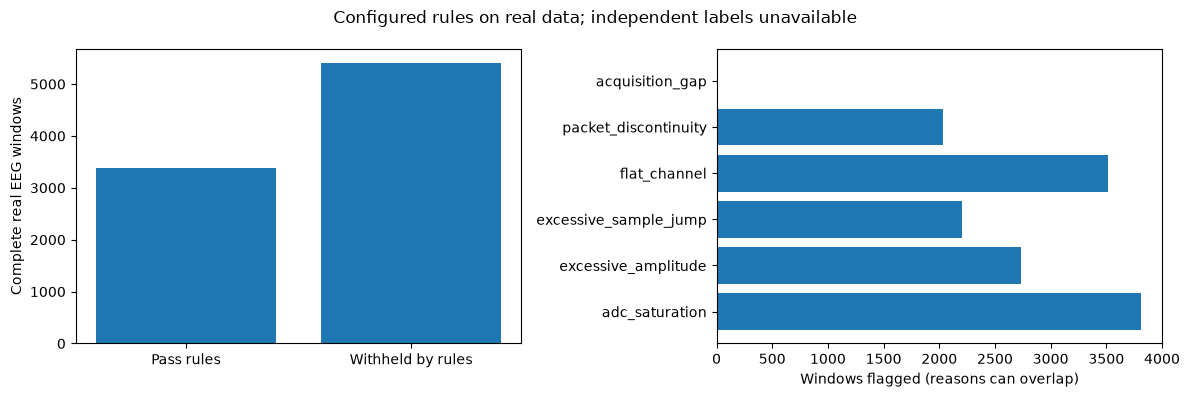

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Pass rules", "Withheld by rules"], [summary["counts"]["acceptable"], summary["counts"]["unacceptable"]])
ax[0].set_ylabel("Complete real EEG windows")
reasons = summary["reason_counts"]
ax[1].barh(list(reasons), list(reasons.values()))
ax[1].set_xlabel("Windows flagged (reasons can overlap)")
fig.suptitle("Configured rules on real data; independent labels unavailable")
fig.tight_layout()
plt.show()


## 9. Inspect actual accepted and rejected windows
Signals are centered **only in the display**. Original values feed the assessor. The threshold policy is conservative: any failing physical channel withholds the entire capture, because silently removing channels would change an existing model's input contract.

Default limits are engineering starting points, not clinically validated cutoffs. Verify device gain and rail level, recording protocol and mains frequency before freezing a deployment policy. Mains is unknown in the files, so 50/60 Hz indicators are reported but line-noise rejection is not enabled by default.

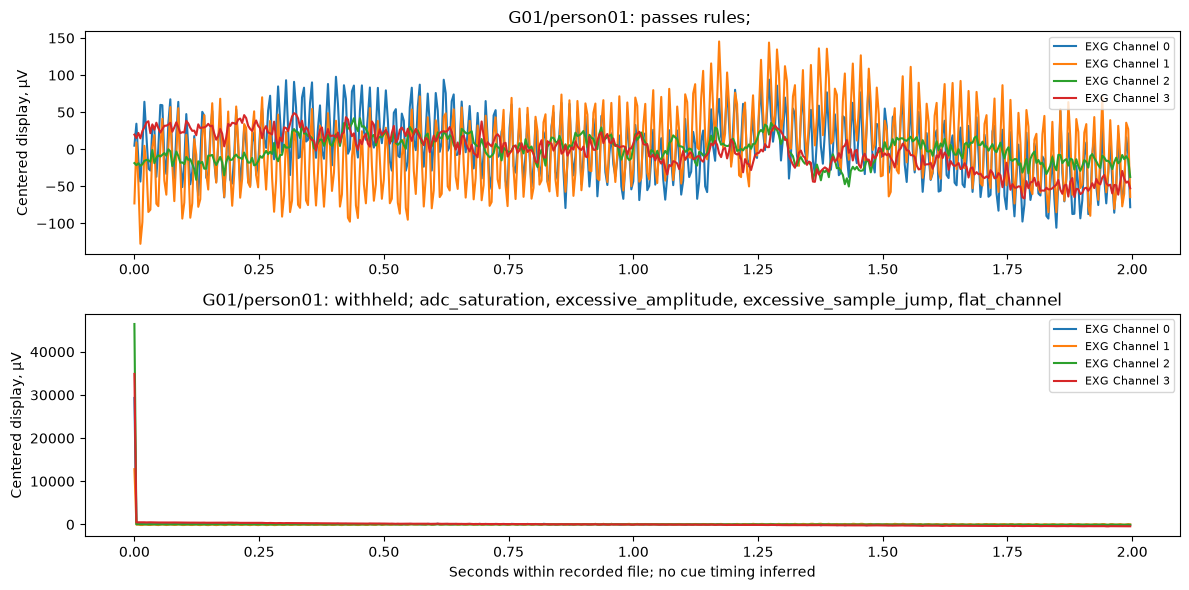

In [10]:
import numpy as np
def original_window(row):
    assert file_sha256(row["source_path"]) == row["source_sha256"]
    capture = read_openbci(row["source_path"])
    a, b = row["source_start_sample"], row["source_end_sample_exclusive"]
    for key in ("raw", "counters", "timestamps"):
        capture[key] = capture[key][:, a:b] if key == "raw" else capture[key][a:b]
    return capture
selected = [next(row for row in rows if row["rule_usable"]), next(row for row in rows if not row["rule_usable"])]
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, row in zip(axes, selected):
    capture = original_window(row)
    report = QualityAssessor(config).assess(**{k:v for k,v in capture.items() if k != "source_kind"})
    assert report["raw_sha256"] == row["raw_sha256"]
    t = np.arange(capture["raw"].shape[1]) / capture["sfreq"]
    for i, name in enumerate(capture["channels"][:4]):
        ax.plot(t, capture["raw"][i] - np.median(capture["raw"][i]), label=name)
    ax.set_title(f"{row['participant_id']}: {'passes rules' if report['usable'] else 'withheld'}; {', '.join(report['reasons'])}")
    ax.set_ylabel("Centered display, µV")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Seconds within recorded file; no cue timing inferred")
fig.tight_layout()
plt.show()


## 10. Withhold an actual unreliable input
The callback below deliberately raises if called. The rejected real window must be withheld before any classifier executes. This demonstrates withholding without inventing a model prediction or connecting to hardware.

In [11]:
rejected = original_window(selected[1])
def must_not_predict(raw):
    raise AssertionError("An unreliable input reached inference")
result = QualityGatedPredictor(QualityAssessor(config)).predict(predict=must_not_predict, **rejected)
assert result["status"] == "withheld" and result["prediction_label"] is None
print(json.dumps({key:result[key] for key in ["status", "command_allowed", "prediction_label", "withholding_reason"]}, indent=2))


{
  "status": "withheld",
  "command_allowed": false,
  "prediction_label": null,
  "withholding_reason": "adc_saturation; excessive_amplitude; excessive_sample_jump; flat_channel"
}


## 11. Independent annotation and training
Copy selected rows from `windows.jsonl` to a separate review file. A reviewer inspects raw waveforms, spectra and continuity under a written quality rubric; ideally two reviewers reconcile disagreements. Set `reviewed_quality_label` to 0 (unacceptable) or 1 (acceptable), `label_verified` to true, reviewer identity and a timezone-aware review timestamp. `annotation_evidence` requires `{path, sha256, locator}` pointing to a separate saved review record, with the locator identifying the window-specific decision.

Do not copy `rule_usable` into the review label. Include both labels across at least five participants; each train/validation/test partition must contain both labels. Record a predefined review sampling protocol to avoid a biased evaluation. The loader verifies provenance and recomputes features from original sources.

Training reports balanced accuracy, macro F1, bad-window average precision, confusion matrix, bad-window acceptance, good-window rejection and coverage. It does not claim calibrated probabilities. Choose deployment policy without selecting the best test fold. A paper should also report reviewer agreement, subject-level uncertainty, an independent test set, and downstream decoder risk versus retained coverage using trustworthy task labels. Missing task cues still limit that last analysis.

In [12]:
# Supply actual independent reviews before enabling training.
REVIEWED_ANNOTATIONS = None  # Path("/absolute/path/reviewed_quality.jsonl")
TRAIN_OUT = PROJECT_ROOT / "signal_quality/data/quality_training_reviewed_v1"
if REVIEWED_ANNOTATIONS is None:
    print("Training skipped: no independent quality labels exist. No production classifier fabricated.")
else:
    from signal_quality.train import train
    training_report = train(REVIEWED_ANNOTATIONS, TRAIN_OUT, config)
    print(json.dumps(training_report, indent=2))


Training skipped: no independent quality labels exist. No production classifier fabricated.


## 12. Avatar integration and limits
`GUI5.py` exposes quality status in `ReadBrain.qml`. Raw OpenBCI is assessed before CNN normalization or the RF request; the same captured samples go to inference. Withheld input clears the old prediction and produces no fallback command. Queued predictions carry approval and are checked again immediately before dispatch. Synthetic input and routes without a verified raw acquisition/model contract are withheld. Manual controls remain available.

This notebook does not validate hardware or the remote model's feature contract. The installed BrainFlow SDK currently fails import because `pkg_resources` is missing; live integration must be checked after repairing that environment. Quality gating cannot guarantee a passing recording contains usable task information, recover lost cues, cancel a command already running, or establish classifier accuracy.